# What makes a car owner reply to a cold DM?

Data: anonymized log of free-shoot cold Instagram DMs (May–Oct 2026), built from the raw sheet with
`python -m src.dmstats data/raw/colddms.csv data/processed/dms.csv`.

**Outcome:** `replied` = owner wrote back at all (any status past "Dead", or a "Dead" row whose notes say they replied).
Secondary: `shot` = the shoot actually happened.

**Analysis set:** 24 rows have no findable DM thread ("no thread found" / "old lead, no thread"). Delivery can't be
verified for them and none replied, so the primary analysis uses the **verified threads** and the full 81 rows are a
sensitivity check.

In [1]:
import sys; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf, statsmodels.api as sm
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.multitest import multipletests
from scipy import stats
from src import dmstats as d

pd.set_option('display.precision', 3)
df = pd.read_csv('../data/processed/dms.csv', parse_dates=['date_sent'])
v = df[df.thread_missing == 0].copy()
print(f'all rows: {len(df)}   verified threads: {len(v)}   send dates: {df.date_sent.nunique()}')

all rows: 81   verified threads: 57   send dates: 17


## 1. Overall rates (95% Wilson CIs)

In [2]:
for name, data in [('all 81', df), ('verified', v)]:
    for y in ['replied', 'shot']:
        k, n = data[y].sum(), len(data); lo, hi = d.wilson(k, n)
        print(f'{name:9s} {y:8s} {k}/{n} = {k/n:.1%}  [{lo:.1%}, {hi:.1%}]')
k, n = v.shot.sum(), v.replied.sum(); lo, hi = d.wilson(k, n)
print(f'shot | replied: {k}/{n} = {k/n:.1%}  [{lo:.1%}, {hi:.1%}]')

all 81    replied  37/81 = 45.7%  [35.3%, 56.5%]
all 81    shot     22/81 = 27.2%  [18.7%, 37.7%]
verified  replied  37/57 = 64.9%  [51.9%, 76.0%]
verified  shot     22/57 = 38.6%  [27.1%, 51.6%]
shot | replied: 22/37 = 59.5%  [43.5%, 73.7%]


### The missing-thread rows are a measurement problem, not a period effect

In [3]:
print(pd.crosstab(df.period, df.thread_missing, margins=True))
print(d.rate_table(df, 'thread_missing'))

thread_missing   0   1  All
period                     
Aug-Oct         28   0   28
May-Jul         29  24   53
All             57  24   81
                 n   k   rate     lo     hi
thread_missing                             
0               57  37  0.649  0.519  0.760
1               24   0  0.000  0.000  0.138


## 2. Reply rate by group (verified threads)

In [4]:
tables = {c: d.rate_table(v, c) for c in ['segment', 'period', 'weekday', 'multi_car']}
for c, t in tables.items(): print(t, '\n')

                 n   k   rate     lo     hi
segment                                    
Other           10   7  0.700  0.397  0.892
Porsche         16  11  0.688  0.444  0.858
BMW             18  12  0.667  0.437  0.837
Italian exotic  13   7  0.538  0.291  0.768 

          n   k   rate     lo     hi
period                              
Aug-Oct  28  21  0.750  0.566  0.873
May-Jul  29  16  0.552  0.375  0.716 

            n   k   rate     lo     hi
weekday                               
Tuesday     7   7  1.000  0.646  1.000
Monday     12  11  0.917  0.646  0.985
Thursday   16  10  0.625  0.386  0.815
Friday     16   7  0.438  0.231  0.668
Wednesday   5   2  0.400  0.118  0.769
Saturday    1   0  0.000  0.000  0.793 

            n   k   rate     lo     hi
multi_car                             
0          50  35  0.700  0.562  0.809
1           7   2  0.286  0.082  0.641 



## 3. Inference

Primary family = 4 tests (segment, period, weekday, multi-car), Holm-corrected. Several cells have expected
counts < 5, so each omnibus test reports a permutation p-value (20k shuffles) alongside the asymptotic one, and
2×2 tests report Fisher's exact p next to the z-test. Effect sizes: Cramér's V for r×c, risk difference
(Newcombe 95% CI) and Cohen's h for 2×2.

In [5]:
seg = d.chi2_perm(v, 'segment')
wd = d.chi2_perm(v, 'weekday')
per = d.two_prop(v[v.period=='Aug-Oct'].replied.sum(), (v.period=='Aug-Oct').sum(),
                 v[v.period=='May-Jul'].replied.sum(), (v.period=='May-Jul').sum())
mc = d.two_prop(v[v.multi_car==1].replied.sum(), (v.multi_car==1).sum(),
                v[v.multi_car==0].replied.sum(), (v.multi_car==0).sum())
wd_cluster_p = d.chi2_cluster_perm(v, 'weekday', 'date_sent', reps=5000)
primary = pd.DataFrame({
    'test': ['segment (chi2, 3 df)', 'weekday (chi2, permuted by send date)', 'period Aug-Oct vs May-Jul', 'multi-car vs single'],
    'p_raw': [seg['p_permutation'], wd_cluster_p, per['fisher_p'], mc['fisher_p']],
    'effect': [f"V={seg['cramers_v']:.2f}", f"V={wd['cramers_v']:.2f}",
               f"diff={per['diff']:+.1%} [{per['diff_lo']:+.1%}, {per['diff_hi']:+.1%}], h={per['h']:.2f}",
               f"diff={mc['diff']:+.1%} [{mc['diff_lo']:+.1%}, {mc['diff_hi']:+.1%}], h={mc['h']:.2f}"],
})
primary['p_holm'] = multipletests(primary.p_raw, method='holm')[1]
print('segment:', {k: round(x, 3) for k, x in seg.items()})
print('weekday (DM-level, assumes independence):', {k: round(x, 3) for k, x in wd.items()})
print(f'weekday (date-level permutation, 17 send dates): p = {wd_cluster_p:.3f}')
print('period z-test p =', round(per['p'], 4), '| Fisher p =', round(per['fisher_p'], 4))
primary

segment: {'chi2': np.float64(0.94), 'dof': 3, 'p_asymptotic': np.float64(0.816), 'p_permutation': np.float64(0.862), 'cramers_v': np.float64(0.128), 'min_expected': np.float64(3.509)}
weekday (DM-level, assumes independence): {'chi2': np.float64(13.954), 'dof': 5, 'p_asymptotic': np.float64(0.016), 'p_permutation': np.float64(0.008), 'cramers_v': np.float64(0.495), 'min_expected': np.float64(0.351)}
weekday (date-level permutation, 17 send dates): p = 0.106
period z-test p = 0.1169 | Fisher p = 0.1665


,test,p_raw,effect,p_holm
0,"segment (chi2, 3 df)",0.862,V=0.13,0.862
1,"weekday (chi2, permuted by send date)",0.106,V=0.49,0.335
2,period Aug-Oct vs May-Jul,0.167,"diff=+19.8% [-4.8%, +41.3%], h=0.42",0.335
3,multi-car vs single,0.084,"diff=-41.4% [-64.5%, -3.3%], h=-0.85",0.335


**Why weekday is permuted by date:** every DM in a batch shares a weekday, and there are only 17 send dates
(Thursday is mostly one 13-DM batch). Shuffling individual DMs pretends there are 57 independent weekday draws;
shuffling weekday across dates is the honest null.

In [6]:
print(v.groupby(['weekday', 'date_sent']).replied.agg(['count', 'sum']))
print('\nsegment x period (why segment and period cannot be separated):')
print(pd.crosstab(v.segment, v.period))

                      count  sum
weekday   date_sent             
Friday    2026-05-22      7    4
          2026-07-10      9    3
Monday    2026-06-01      2    2
          2026-07-13      2    2
          2026-08-03      7    7
          2026-09-28      1    0
Saturday  2026-07-04      1    0
Thursday  2026-09-03      1    1
          2026-09-17      2    2
          2026-10-01     13    7
Tuesday   2026-05-12      2    2
          2026-05-19      2    2
          2026-09-08      1    1
          2026-09-15      2    2
Wednesday 2026-05-13      4    1
          2026-08-19      1    1

segment x period (why segment and period cannot be separated):
period          Aug-Oct  May-Jul
segment                         
BMW                   0       18
Italian exotic       11        2
Other                 4        6
Porsche              13        3


Post-hoc: each segment vs. the rest (Holm within this family). Shown for effect sizes; the omnibus test above is the decision.

In [7]:
d.each_vs_rest(v, 'segment')[['p1', 'p2', 'diff', 'diff_lo', 'diff_hi', 'h', 'fisher_p', 'p_holm']]

,p1,p2,diff,diff_lo,diff_hi,h,fisher_p,p_holm
group,,,,,,,,
Other,0.700,0.638,0.062,-0.265,0.301,0.131,1.000,1.0
Porsche,0.688,0.634,0.053,-0.223,0.283,0.113,0.767,1.0
BMW,0.667,0.641,0.026,-0.239,0.257,0.054,1.000,1.0
Italian exotic,0.538,0.682,-0.143,-0.417,0.129,-0.295,0.509,1.0


### Sensitivity: all 81 rows (treating missing threads as non-replies)
This is what a naive analysis would report. The period gap balloons because every missing thread is in May–Jul.

In [8]:
per_all = d.two_prop(df[df.period=='Aug-Oct'].replied.sum(), (df.period=='Aug-Oct').sum(),
                     df[df.period=='May-Jul'].replied.sum(), (df.period=='May-Jul').sum())
print({k: round(x, 4) for k, x in per_all.items()})
print({k: round(x, 4) for k, x in d.chi2_perm(df, 'segment').items()})

{'p1': np.float64(0.75), 'p2': np.float64(0.3019), 'diff': np.float64(0.4481), 'diff_lo': np.float64(0.2212), 'diff_hi': np.float64(0.6111), 'h': np.float64(0.931), 'z': np.float64(3.8505), 'p': np.float64(0.0001), 'fisher_p': np.float64(0.0002)}


{'chi2': np.float64(1.3189), 'dof': 3, 'p_asymptotic': np.float64(0.7247), 'p_permutation': np.float64(0.7496), 'cramers_v': np.float64(0.1276), 'min_expected': np.float64(6.8519)}


## 4. Logistic regression

`replied ~ segment + period` on verified threads, SEs clustered by send date (DMs sent the same day share a
template and a moment, so they aren't independent). Weekday and multi-car are left out: 57 rows with 20 non-replies
gives ~5 events per parameter already, well under the usual 10.

In [9]:
v['date_id'] = v.date_sent.factorize()[0]
f = 'replied ~ C(segment, Treatment("BMW")) + C(period, Treatment("May-Jul"))'
m = smf.glm(f, v, family=sm.families.Binomial()).fit(cov_type='cluster', cov_kwds={'groups': v.date_id})
ors = pd.DataFrame({'OR': np.exp(m.params), 'lo': np.exp(m.conf_int()[0]), 'hi': np.exp(m.conf_int()[1]), 'p': m.pvalues})
print(m.summary().tables[1]); ors

                                                     coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------------------------
Intercept                                          0.6931      0.438      1.584      0.113      -0.164       1.551
C(segment, Treatment("BMW"))[T.Italian exotic]    -2.9667      2.013     -1.474      0.141      -6.912       0.979
C(segment, Treatment("BMW"))[T.Other]             -0.5538      0.429     -1.290      0.197      -1.395       0.288
C(segment, Treatment("BMW"))[T.Porsche]           -2.0697      1.322     -1.566      0.117      -4.660       0.521
C(period, Treatment("May-Jul"))[T.Aug-Oct]         2.7606      1.472      1.875      0.061      -0.125       5.647


,OR,lo,hi,p
Intercept,2.000,8.484e-01,4.715,0.113
"C(segment, Treatment(""BMW""))[T.Italian exotic]",0.051,9.955e-04,2.661,0.141
"C(segment, Treatment(""BMW""))[T.Other]",0.575,2.477e-01,1.333,0.197
"C(segment, Treatment(""BMW""))[T.Porsche]",0.126,9.464e-03,1.684,0.117
"C(period, Treatment(""May-Jul""))[T.Aug-Oct]",15.809,8.822e-01,283.307,0.061


In [10]:
# LR test: does segment add anything once period is in?
full = smf.glm(f, v, family=sm.families.Binomial()).fit()
red = smf.glm('replied ~ C(period)', v, family=sm.families.Binomial()).fit()
lr = 2 * (full.llf - red.llf); print(f'LR = {lr:.2f}, df = 3, p = {stats.chi2.sf(lr, 3):.3f}')
print(f'non-replies = {(v.replied==0).sum()}, params = {len(full.params)-1}, EPV = {(v.replied==0).sum()/(len(full.params)-1):.1f}')

LR = 6.65, df = 3, p = 0.084
non-replies = 20, params = 4, EPV = 5.0


## 5. Power / sample size

In [11]:
pw = NormalIndPower()
n_a, n_b = (v.period=='Aug-Oct').sum(), (v.period=='May-Jul').sum()
mde_h = pw.solve_power(nobs1=n_a, ratio=n_b/n_a, alpha=0.05, power=0.8)
print(f'period: n={n_a} vs {n_b}; detectable |h| at 80% power = {mde_h:.2f}; observed h = {per["h"]:.2f}; '
      f'power for observed = {pw.power(per["h"], n_a, 0.05, ratio=n_b/n_a):.2f}')
n_need = pw.solve_power(effect_size=abs(per['h']), alpha=0.05, power=0.8)
print(f'n per group to detect observed period effect at 80%: {np.ceil(n_need):.0f}')
p_por, p_bmw = tables['segment'].loc['Porsche', 'rate'], tables['segment'].loc['BMW', 'rate']
h_seg = d.cohens_h(p_por, p_bmw)
print(f'Porsche vs BMW: {p_por:.1%} vs {p_bmw:.1%}, h = {h_seg:.2f}; '
      f'n per group needed at 80%: {np.ceil(pw.solve_power(effect_size=abs(h_seg), alpha=0.05, power=0.8)):.0f}')
for h in [0.2, 0.5]:
    print(f'n per group for h={h}: {np.ceil(pw.solve_power(effect_size=h, alpha=0.05, power=0.8)):.0f}')

period: n=28 vs 29; detectable |h| at 80% power = 0.74; observed h = 0.42; power for observed = 0.35
n per group to detect observed period effect at 80%: 90
Porsche vs BMW: 68.8% vs 66.7%, h = 0.04; n per group needed at 80%: 7906
n per group for h=0.2: 393
n per group for h=0.5: 63


## 6. Charts

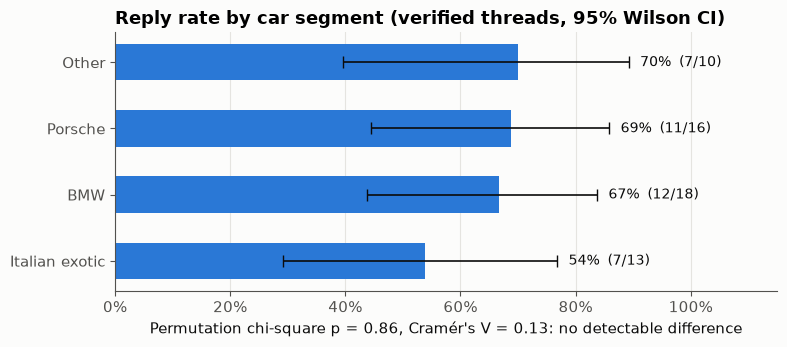

In [12]:
BLUE, ORANGE, INK, MUTED, SURF = '#2a78d6', '#eb6834', '#0b0b0b', '#52514e', '#fcfcfb'
plt.rcParams.update({'figure.facecolor': SURF, 'axes.facecolor': SURF, 'axes.edgecolor': MUTED, 'axes.labelcolor': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
                     'font.size': 11, 'axes.titlesize': 13, 'axes.titleweight': 'bold'})

def rate_bars(ax, t, color):
    y = np.arange(len(t))[::-1]
    ax.barh(y, t.rate, color=color, height=0.55)
    ax.errorbar(t.rate, y, xerr=[t.rate - t.lo, t.hi - t.rate], fmt='none', ecolor=INK, capsize=4, lw=1.2)
    for yi, (idx, r) in zip(y, t.iterrows()):
        ax.text(r.hi + 0.02, yi, f'{r.rate:.0%}  ({r.k:.0f}/{r.n:.0f})', va='center', color=INK, fontsize=10)
    ax.set_yticks(y, t.index); ax.set_xlim(0, 1.15); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:.0%}'))
    ax.grid(axis='x', color='#e5e4e0', lw=0.8); ax.set_axisbelow(True)

fig, ax = plt.subplots(figsize=(8, 3.6))
rate_bars(ax, tables['segment'], BLUE)
ax.set_title('Reply rate by car segment (verified threads, 95% Wilson CI)', loc='left')
ax.set_xlabel(f"Permutation chi-square p = {seg['p_permutation']:.2f}, Cramér's V = {seg['cramers_v']:.2f}: no detectable difference")
fig.tight_layout(); fig.savefig('../figures/reply_by_segment.png', dpi=160)

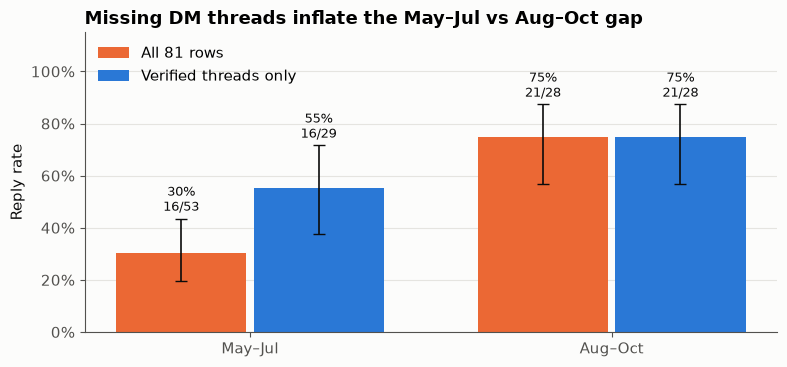

In [13]:
rows = []
for label, data in [('All 81 rows', df), ('Verified threads only', v)]:
    for p, g in data.groupby('period'):
        k, n = g.replied.sum(), len(g); lo, hi = d.wilson(k, n); rows.append((label, p, k, n, k/n, lo, hi))
r = pd.DataFrame(rows, columns=['set', 'period', 'k', 'n', 'rate', 'lo', 'hi'])
fig, ax = plt.subplots(figsize=(8, 3.8)); x = np.arange(2); w = 0.36
for i, (label, col) in enumerate([('All 81 rows', ORANGE), ('Verified threads only', BLUE)]):
    s = r[r.set == label].set_index('period').loc[['May-Jul', 'Aug-Oct']]
    xs = x + (i - 0.5) * (w + 0.02)
    ax.bar(xs, s.rate, w, color=col, label=label)
    ax.errorbar(xs, s.rate, yerr=[s.rate - s.lo, s.hi - s.rate], fmt='none', ecolor=INK, capsize=4, lw=1.2)
    for xi, (_, row) in zip(xs, s.iterrows()):
        ax.text(xi, row.hi + 0.03, f'{row.rate:.0%}\n{row.k}/{row.n}', ha='center', color=INK, fontsize=9)
ax.set_xticks(x, ['May–Jul', 'Aug–Oct']); ax.set_ylim(0, 1.15)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y:.0%}')); ax.grid(axis='y', color='#e5e4e0', lw=0.8); ax.set_axisbelow(True)
ax.legend(frameon=False, loc='upper left'); ax.set_ylabel('Reply rate')
ax.set_title('Missing DM threads inflate the May–Jul vs Aug–Oct gap', loc='left')
fig.tight_layout(); fig.savefig('../figures/period_missing_threads.png', dpi=160)

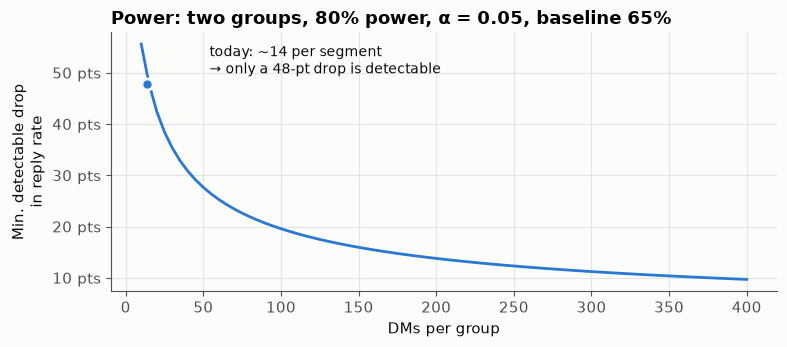

In [14]:
base = v.replied.mean(); ns = np.arange(10, 401, 5)
mde = [base - np.sin((2*np.arcsin(np.sqrt(base)) - pw.solve_power(nobs1=n, alpha=0.05, power=0.8)) / 2) ** 2 for n in ns]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(ns, np.array(mde), color=BLUE, lw=2)
n_now = len(v) // 4; mde_now = mde[np.abs(ns - n_now).argmin()]
ax.plot([n_now], [mde_now], 'o', ms=8, color=BLUE, mec=SURF, mew=2)
ax.annotate(f'today: ~{n_now} per segment\n→ only a {mde_now*100:.0f}-pt drop is detectable', (n_now, mde_now),
            xytext=(n_now + 40, mde_now + 0.02), color=INK, fontsize=10)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f'{y*100:.0f} pts')); ax.grid(color='#e5e4e0', lw=0.8); ax.set_axisbelow(True)
ax.set_xlabel('DMs per group'); ax.set_ylabel('Min. detectable drop\nin reply rate')
ax.set_title(f'Power: two groups, 80% power, α = 0.05, baseline {base:.0%}', loc='left')
fig.tight_layout(); fig.savefig('../figures/power_curve.png', dpi=160)